# 2. Can lunar angle measurements support halo-orbit station-keeping?

Three simulated **lunar surface observatories (LSOs)** track a spacecraft in a near-rectilinear halo orbit (NRHO). Each visible LSO reports two line-of-sight angles: right ascension ($\alpha$) and declination ($\delta$). The estimator combines these observations with past burn commands to infer the spacecraft's **position and velocity departure** from the reference orbit. The planner uses that estimate to choose the timing and three-axis velocity change ($\Delta v$) of a corrective burn. The corridor allows up to **10 km** of position departure and **0.1 m/s** of velocity departure.

### Where the command and noise enter

- **Burn path ($G$).** The commanded burn $u_k$ changes velocity through actuator gains $g(\phi_k)$. Gravity propagates the resulting departure $e$ and the LSO geometry maps it to angles. The LSO measurement at epoch $k$ comes before the burn at $k$, so the first affected sampled angle is at $k+1$.
- **Noise path ($H$).** The simulator adds independent Gaussian sensor noise ($1$ arcsec standard deviation) to each ideal angle and then applies the visibility mask. The filter also allows state prediction uncertainty through $Q$, including burn uncertainty in the annual extended filter. A state disturbance can propagate into future angles, even when the sensor noise itself is white.

$$
e_{k+1}=A_k e_k+B_k\operatorname{diag}(g(\phi_k))u_k+w_k,\qquad
z_{j,k}-\bar z_{j,k}\approx C_{j,k}e_k+v_{j,k}.
$$

$A_k$ is the state-transition matrix (STM) that propagates a small departure for one sample. $B_k$ maps the burn through that step. $C_{j,k}$ is the local slope of the sightline angles with respect to the departure. The filter uses only its visible rows. The nonlinear simulation supplies the spacecraft truth for scoring and generating synthetic observations. The fit uses the measured angles and commands. A grey box is appropriate because the orbit and sensor geometry give $A_k$, $B_k$ and $C_{j,k}$ directly, leaving the actuator gains to be estimated from data.

## 1. Are the measured angles stationary?

First subtract the angle predicted on the reference orbit. This accounts for the nominal sightline motion and leaves the **measured angle offset**, which still contains spacecraft departure and sensor noise. We use the longest uninterrupted test run for each angle and print its trajectory seed and length. We also compare means and variances across four subsegments with correlation-aware bands, as in Studio 6. A flag counts a subsegment outside the approximate 95% band around the segment average.

At the 5% level, **ADF** tests a unit-root null and **KPSS** tests a constant-level stationarity null. ADF rejection plus KPSS non-rejection supports level stationarity for that run. If both reject, some behavior departs from the simple level-stationary model even though ADF rejects a unit root. The tests describe these observed records. The phase dependence of the spacecraft dynamics is a separate question.

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown
from halo_tracking import stationkeeping as physics
from halo_tracking import lso_stationkeeping as sk
from halo_tracking import stationkeeping_diagnostics as sd
from halo_tracking import lso_diagnostics as ld
from halo_tracking import lso_report_plots as plots
ROOT=Path.cwd()
if not (ROOT/'configs').exists(): ROOT=ROOT.parent
OUT=ROOT/'artifacts'/'stationkeeping'
OUT.mkdir(parents=True,exist_ok=True)
plots.style()
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

orbit,data=sk.restore_study(ROOT,OUT/'data')
test = data['test']
alpha = orbit.settings['alpha']
offsets = sk.measured_angle_offsets(orbit, test)
angle_rows = ld.stationarity_rows(offsets)

def test_p(value):
    return '—' if value is None else f'{value:.3g}'

table(['Measured offset','Test seed','Consecutive samples','ADF p','KPSS p*',
       'Mean flags / 4','Variance flags / 4','Reading'],
      [(r['channel'],test.seeds[r['arc']],r['contiguous_samples'],
        test_p(r['adf_p']),test_p(r['kpss_p']),r.get('mean_flags','—'),
        r.get('variance_flags','—'),r['reading']) for r in angle_rows])
print('* KPSS reports table bounds when the p-value falls outside its tabulation.')
readings = {
    'supports level stationarity': 'The run supports a constant level by ADF and KPSS. Check the segment flags for changes these two tests may miss.',
    'conflicting tests': 'ADF rejects a unit root and KPSS rejects level stationarity. A model with a constant mean over this run is questionable.',
    'evidence against level stationarity': 'KPSS rejects a constant level and ADF cannot rule out a unit root. Treat a constant level over this run as unsupported.',
    'inconclusive / low power': 'Neither test rejects. The run gives too little evidence to decide whether a constant level is reasonable.',
    'insufficient contiguous observations': 'Visibility leaves too few consecutive angles for these tests.'
}
for r in angle_rows:
    name, angle = r['channel'].rsplit(' ',1)
    flags = ''
    if r.get('mean_flags', 0) or r.get('variance_flags', 0):
        flags = (f" The segment check flags {r['mean_flags']} means and "
                 f"{r['variance_flags']} variances out of four.")
    display(Markdown(f"**{name} {angle} ({'declination' if angle == 'delta' else 'right ascension'}).** "
                     + readings[r['reading']] + flags))
(OUT/'measured_angle_stationarity.json').write_text(json.dumps(angle_rows,indent=2)+'\n')

* KPSS reports table bounds when the p-value falls outside its tabulation.
Out[1]: 2118


| Measured offset | Test seed | Consecutive samples | ADF p | KPSS p* | Mean flags / 4 | Variance flags / 4 | Reading |
| --- | --- | --- | --- | --- | --- | --- | --- |
| LSO 1 alpha | 8960 | 63 | 0.482 | 0.1 | 0 | 4 | inconclusive / low power |
| LSO 1 delta | 8960 | 63 | 0.289 | 0.01 | 1 | 1 | evidence against level stationarity |
| LSO 2 alpha | 8960 | 30 | 0.00011 | 0.0898 | 1 | 0 | supports level stationarity |
| LSO 2 delta | 8960 | 30 | 1 | 0.1 | 1 | 1 | inconclusive / low power |
| LSO 3 alpha | 8960 | 71 | 0.162 | 0.0299 | 1 | 0 | evidence against level stationarity |
| LSO 3 delta | 8960 | 71 | 0.159 | 0.01 | 2 | 0 | evidence against level stationarity |

**LSO 1 alpha (right ascension).** Neither test rejects. The run gives too little evidence to decide whether a constant level is reasonable. The segment check flags 0 means and 4 variances out of four.

**LSO 1 delta (declination).** KPSS rejects a constant level and ADF cannot rule out a unit root. Treat a constant level over this run as unsupported. The segment check flags 1 means and 1 variances out of four.

**LSO 2 alpha (right ascension).** The run supports a constant level by ADF and KPSS. Check the segment flags for changes these two tests may miss. The segment check flags 1 means and 0 variances out of four.

**LSO 2 delta (declination).** Neither test rejects. The run gives too little evidence to decide whether a constant level is reasonable. The segment check flags 1 means and 1 variances out of four.

**LSO 3 alpha (right ascension).** KPSS rejects a constant level and ADF cannot rule out a unit root. Treat a constant level over this run as unsupported. The segment check flags 1 means and 0 variances out of four.

**LSO 3 delta (declination).** KPSS rejects a constant level and ADF cannot rule out a unit root. Treat a constant level over this run as unsupported. The segment check flags 2 means and 0 variances out of four.

## 2. How does a burn change the measured angles?

$G$ is a **phase-dependent** command-to-angle map. For a burn at epoch $k$, the first-sample map is $C_{k+1}B_k\operatorname{diag}(g_k)$. At later samples, the intervening STMs propagate that same departure before the observation map acts. The table compares the ideal responses at several equally spaced burn phases. An LSO supplies those angles to the filter only when visible.

The eigenvalues of the product of STMs over one complete orbit are **Floquet multipliers**. They describe the modes that grow, decay, or oscillate from orbit to orbit. Both gain fits share these open-loop modes because the fitted gains appear in $B_k\operatorname{diag}(g_k)$, while the homogeneous dynamics depend on $A_k$. A single set of LTI transfer-function poles and zeros would require time-invariant channels. A lifted periodic input–output zero analysis would also require specifying a repeating measurement schedule and the input/output channels, so this study reports the physical modes and the phase-dependent response directly.

In [2]:
from halo_tracking.measurements import ARCSEC

horizon = orbit.settings['horizon_steps']
burn_phases = np.arange(4) * orbit.n // 4
response_rows = []
for k in burn_phases:
    response = orbit.B[k] * 1e-3  # unit test input of 1 mm/s on each axis
    _, c_next = orbit.observation_terms(k + 1)
    first = np.linalg.norm(c_next @ response) / ARCSEC
    for j in range(1, horizon):
        response = orbit.A[(k+j) % orbit.n] @ response
    _, c_end = orbit.observation_terms(k + horizon)
    last = np.linalg.norm(c_end @ response) / ARCSEC
    response_rows.append((360*k/orbit.n, first, last))
table(['Burn phase [deg]','First sample [arcsec]',f'Sample +{horizon} [arcsec]'],
      [(f'{p:.0f}',f'{a:.3f}',f'{b:.3f}') for p,a,b in response_rows])
display(Markdown('Each value combines the ideal six-angle responses to three separate 1 mm/s '
                 'axis burns using unit actuator gains. The change across rows shows that '
                 'the same commanded burn can yield different angles at different orbit phases.'))
monodromy = np.eye(6)
for transition in orbit.A:
    monodromy = transition @ monodromy
modes = sorted(np.linalg.eigvals(monodromy),key=abs,reverse=True)
table(['Mode','Multiplier','Magnitude','Phase [deg/orbit]'],
      [(i,f'{m:.5g}',f'{abs(m):.5g}',f'{np.angle(m,deg=True):.3g}')
       for i,m in enumerate(modes,1)])
display(Markdown(f'**Open-loop stability.** The dominant mode grows by about {abs(modes[0]):.3g}× '
                 'per orbit in the local model. This growth motivates corrective burns.'))
(OUT/'phase_response.json').write_text(json.dumps(dict(
    response=response_rows, multipliers=[[m.real,m.imag] for m in modes]),indent=2)+'\n')

Out[2]: 708


| Burn phase [deg] | First sample [arcsec] | Sample +8 [arcsec] |
| --- | --- | --- |
| 0 | 0.085 | 0.646 |
| 90 | 0.081 | 0.757 |
| 180 | 0.088 | 0.613 |
| 270 | 0.082 | 0.689 |

Each value combines the ideal six-angle responses to three separate 1 mm/s axis burns using unit actuator gains. The change across rows shows that the same commanded burn can yield different angles at different orbit phases.

| Mode | Multiplier | Magnitude | Phase [deg/orbit] |
| --- | --- | --- | --- |
| 1 | -3.0479+0j | 3.0479 | 180 |
| 2 | 1+5.4766e-05j | 1 | 0.00314 |
| 3 | 1-5.4766e-05j | 1 | -0.00314 |
| 4 | 0.31232+0.94998j | 1 | 71.8 |
| 5 | 0.31232-0.94998j | 1 | -71.8 |
| 6 | -0.32809+0j | 0.32809 | 180 |

**Open-loop stability.** The dominant mode grows by about 3.05× per orbit in the local model. This growth motivates corrective burns.

## Welch and FRF checks on the training commands

The Welch estimate below uses the known training commands and the reconstructed position from the baseline LSO filter. It checks how much frequency resolution and command-to-estimate coherence the record provides. The estimated FRF includes the filter and samples from different orbital phases. Section 2 computes the physical phase-dependent command-to-angle map. The held-out residual section checks $G$ and $H$ using measured angles.

In [3]:
training = data['training']
welch = {}
for L in sorted({orbit.settings['welch_length'], orbit.n}):
    welch[L] = sd.welch_bundle(training.u, training.y[:,:-1], 1/orbit.dt_s, L)
table(['Window samples','Resolution [cycles/day]','Windows','Supported nonzero bins',
       'X/Y/Z bins meeting coherence screen'],
      [(L, f'{86400/(orbit.dt_s*L):.3g}', q['segments'],
        f"{np.sum(q['supported'][1:])}/{len(q['supported'])-1}",
        ' / '.join(str(np.count_nonzero(q['coherence'][1:,c,c][q['supported'][1:]]
                       >= orbit.settings['coherence_threshold'])) for c in range(3)))
       for L,q in welch.items()])
print(f"The pairwise coherence screen is {orbit.settings['coherence_threshold']:.2f}. "
      "Short windows yield more averages. Full-orbit windows resolve one cycle per orbit.")

The pairwise coherence screen is 0.80. Short windows yield more averages. Full-orbit windows resolve one cycle per orbit.


| Window samples | Resolution [cycles/day] | Windows | Supported nonzero bins | X/Y/Z bins meeting coherence screen |
| --- | --- | --- | --- | --- |
| 32 | 0.496 | 56 | 16/16 | 0 / 0 / 0 |
| 128 | 0.124 | 8 | 64/64 | 0 / 0 / 0 |

## 3. Do the trajectories support phase-dependent actuator gains?

The **global-gain** model pools all training trajectories and phases into one gain per burn axis. The **periodic-gain** model pools independent passes through the same orbital phases, interpolates between six overlapping phase windows, and smooths neighboring gains across the end of the orbit. Both use phase-dependent STMs and measurement geometry. The simulator uses constant actuator gains, so phase-dependent fitted gains can absorb discrepancies between the nonlinear simulation and the linearized predictor.

The fit minimizes joint, covariance-standardized one-step angular innovations on eight open-loop training trajectories. Four independent trajectories support validation and four support the final test. For the BIC comparison, fit the phase-window alternatives **without** smoothing on the same training epochs. The nominal BIC difference combines the Gaussian innovation sum of squares and the parameter penalty $d\log N$ (with $N$ measured epochs and $d$ gain coefficients). The innovation covariance schedule is fixed across the candidates, so its log-determinant cancels. The criterion is a relative comparison under the working innovation model. Short records and residual dependence limit its interpretation. The smoothed six-window candidate is evaluated separately with the global model for the test and annual trial.

In [4]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown
from halo_tracking import stationkeeping as physics
from halo_tracking import lso_stationkeeping as sk
from halo_tracking import stationkeeping_diagnostics as sd
from halo_tracking import lso_diagnostics as ld
from halo_tracking import lso_report_plots as plots
ROOT=Path.cwd()
if not (ROOT/'configs').exists(): ROOT=ROOT.parent
OUT=ROOT/'artifacts'/'stationkeeping'
OUT.mkdir(parents=True,exist_ok=True)
plots.style()
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

orbit,data=sk.restore_study(ROOT,OUT/'data')
global_fit=sk.fit_greybox(orbit,data['training'])
fit=sk.fit_periodic_greybox(orbit,data['training'],
    windows=orbit.settings['periodic_gain_windows'],
    smoothing=orbit.settings['periodic_gain_smoothing'])
gains=fit['gains']
models={'Global gains':global_fit['gains'],'Periodic gains':gains}
table(['Phase [deg]','X gain','Y gain','Z gain'],
      [(f'{phase:.0f}',*(f'{value:.4f}' for value in local))
       for phase,local in zip(fit['knot_phase_deg'],fit['knot_gains'])])
print('Global gains:',global_fit['gains'])

def save_fit(name, result):
    values={k:v.tolist() if isinstance(v,np.ndarray) else v for k,v in result.items()}
    (OUT/name).write_text(json.dumps(values,indent=2)+'\n')

save_fit('greybox_fit.json',fit)
save_fit('global_greybox_fit.json',global_fit)

training = data['training']
window_counts = sorted({3, fit['windows']})
n_epochs = int(training.visible.any(axis=-1).sum())
candidates = [('Global',3,global_fit['cost'],global_fit['gains'])]
for windows in window_counts:
    candidate = sk.fit_periodic_greybox(orbit, training, windows=windows, smoothing=0)
    candidates.append((f'{windows} phase windows',3*windows,
                       candidate['training_cost'],candidate['gains']))
selection = []
for name, d, cost, candidate_gains in candidates:
    validation = sk.predict(orbit, data['validation'], candidate_gains)['standardized']
    selection.append(dict(model=name, d=d, training_sum_squares=2*cost,
                          bic_relative=2*cost+d*np.log(n_epochs),
                          validation_rms=float(np.sqrt(np.nanmean(validation**2)))))
best = min(selection,key=lambda r:r['bic_relative'])
table(['Training candidate','Gain coefficients','Training sum of squares','ΔBIC','Validation RMS [standardized]'],
      [(r['model'],r['d'],f"{r['training_sum_squares']:.1f}",
        f"{r['bic_relative']-best['bic_relative']:.2f}",f"{r['validation_rms']:.3f}") for r in selection])
best_validation = min(selection,key=lambda r:r['validation_rms'])
display(Markdown(f"**Model selection.** The lowest nominal BIC is **{best['model']}**. "
                 f"The lowest validation innovation RMS is **{best_validation['model']}**. "
                 "Lower BIC favors explaining the data with fewer gain coefficients. "
                 "The validation score checks how well those gains predict angles on new trajectories."))
(OUT/'gain_model_selection.json').write_text(json.dumps(selection,indent=2)+'\n')

Global gains: [0.98926963 1.03752361 0.95475186]
Out[4]: 539


| Phase [deg] | X gain | Y gain | Z gain |
| --- | --- | --- | --- |
| 0 | 0.9584 | 1.0745 | 1.0392 |
| 60 | 0.9866 | 1.0463 | 1.0367 |
| 120 | 0.9968 | 1.0497 | 1.0139 |
| 180 | 0.9837 | 1.0587 | 0.9111 |
| 240 | 0.9929 | 1.0154 | 0.9927 |
| 300 | 0.9808 | 1.0354 | 1.0255 |

| Training candidate | Gain coefficients | Training sum of squares | ΔBIC | Validation RMS [standardized] |
| --- | --- | --- | --- | --- |
| Global | 3 | 3871.5 | 0.00 | 1.188 |
| 3 phase windows | 9 | 3864.3 | 34.40 | 1.188 |
| 6 phase windows | 18 | 3851.8 | 84.38 | 1.192 |

**Model selection.** The lowest nominal BIC is **Global**. The lowest validation innovation RMS is **Global**. Lower BIC favors explaining the data with fewer gain coefficients. The validation score checks how well those gains predict angles on new trajectories.

## 4. Do the angular updates improve held-out navigation?

Compare each model's state estimate against the simulator's truth. The free prediction uses the first angular update and the known burn commands, then coasts without more angles. The updated estimate uses angles every time an LSO is visible. The angular RMSE below is the one-step error **before** using that epoch's measurement.

| Split | Model | Angular RMSE [arcsec] | Navigation position RMSE [km] | Navigation velocity RMSE [m/s] |
| --- | --- | --- | --- | --- |
| validation | Global gains | 2.23 | 0.391 | 0.00474 |
| test | Global gains | 2.44 | 0.372 | 0.00414 |
| validation | Periodic gains | 2.28 | 0.411 | 0.00481 |
| test | Periodic gains | 2.43 | 0.371 | 0.00411 |

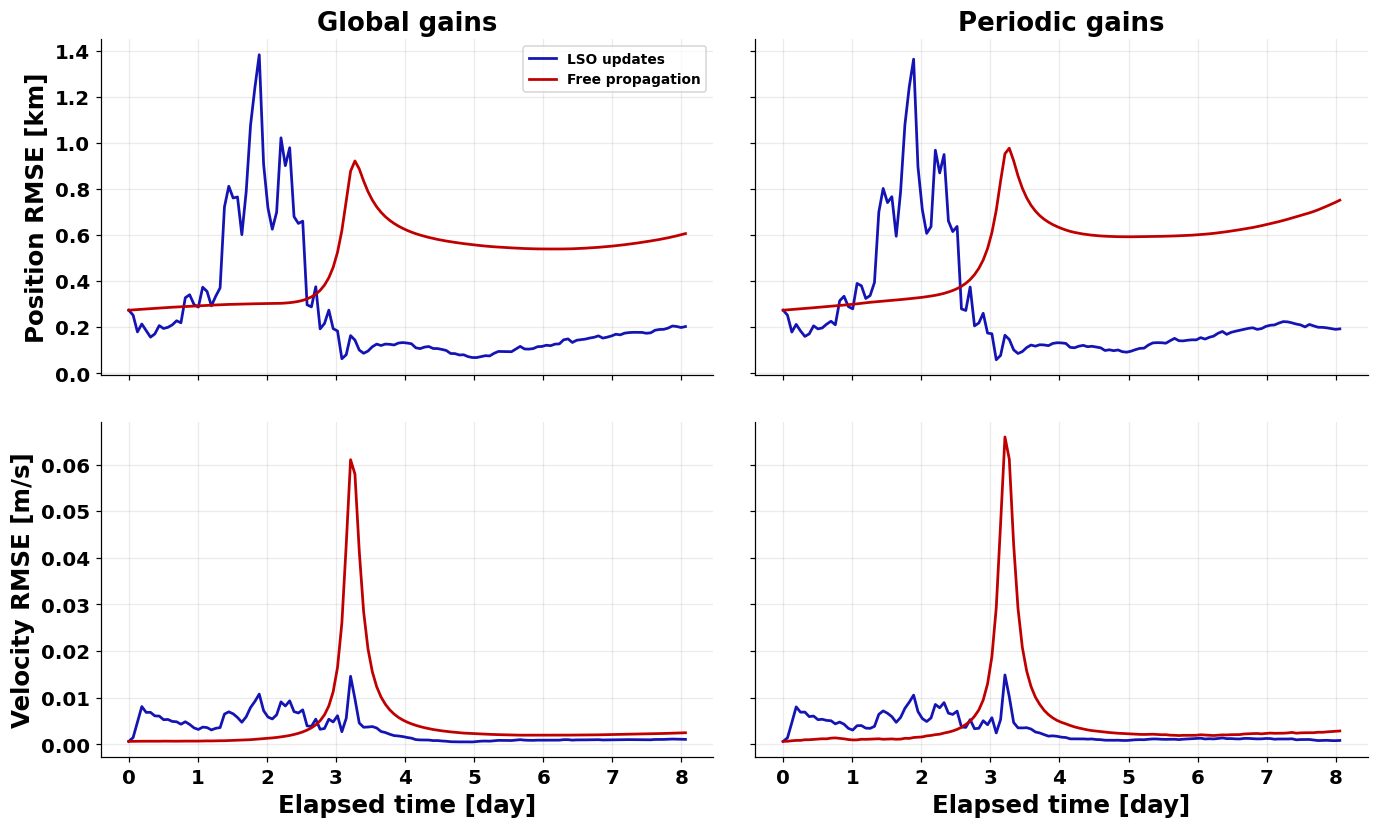

**Purpose:** Shared scales compare held-out prediction errors for the same trajectories.

**Result:** The blue traces show how LSO updates change the state errors for each fitted gain model.

**Global gains.** Test position RMSE is 0.372 km with angle updates and 0.512 km in free prediction.

**Periodic gains.** Test position RMSE is 0.371 km with angle updates and 0.561 km in free prediction.

In [5]:
scores={model:{split:sk.prediction_scores(orbit,rec,model_gains) for split,rec in data.items()}
        for model,model_gains in models.items()}
table(['Split','Model','Angular RMSE [arcsec]','Navigation position RMSE [km]','Navigation velocity RMSE [m/s]'],
      [(split,model,f"{q['angular_innovation_rmse_arcsec']:.3g}",
        f"{q['navigation']['position_rmse_km']:.3g}",f"{q['navigation']['velocity_rmse_m_s']:.3g}")
       for model,result in scores.items() for split,q in result.items() if split != 'training'])
(OUT/'prediction_scores.json').write_text(json.dumps(scores['Periodic gains'],indent=2)+'\n')
(OUT/'model_comparison_scores.json').write_text(json.dumps(scores,indent=2)+'\n')
test=data['test']
predictions={label:(sk.predict(orbit,test,local),sk.predict(orbit,test,local,free_run=True))
             for label,local in models.items()}
pred,free=predictions['Periodic gains']
plots.compare_heldout(orbit,test,predictions,OUT/'figures')
np.savez_compressed(OUT/'test_predictions.npz',**pred,free_simulation=free['navigation'])
for label, q in scores.items():
    pos = q['test']['navigation']['position_rmse_km']
    coast = q['test']['free_run']['position_rmse_km']
    display(Markdown(f"**{label}.** Test position RMSE is {pos:.3f} km with angle updates "
                     f"and {coast:.3f} km in free prediction."))

## 5. Do the residuals support the burn path $G$ and the noise path $H$?

An **innovation** is a measured angle minus its one-step prediction. For this check, the filter standardizes the innovations jointly using its predicted covariance, including correlations among visible angles at the same epoch. These standardized coordinates can mix visible angles, so the whiteness check refers to predictor coordinates. Section 1 reports the individual measured angles.

- **$G$, input–output dynamics.** If past commands still correlate with the innovation, the model may have missed a burn response. We correlate $u_k$ with the innovation at $k+1$ and later, across all three axes and all supported standardized coordinates. We redraw the independent open-loop commands for a maximum-correlation reference while keeping residuals and masks fixed. This screen preserves residual serial dependence and uses observed visibility as fixed. Its conclusion applies to the tested excitation, lags and measurements. The simulated visibility can depend on the trajectory, so this is a screening p-value conditional on the observed mask.
- **$H$, noise and uncertainty.** If the filter models the predictable part of the angle errors, the innovations should have little residual serial correlation. Ljung–Box tests the longest uninterrupted run in each eligible test trajectory and coordinate. Holm adjustment accounts for the eligible family within each model. The error plots use original sample lags and omit missing pairs. A rejection can reflect dynamics, uncertainty tuning, or the measurement model, even though the simulated sensor noise is white by construction.

Eligible runs use at least 24 consecutive samples. The input screen covers command-to-angle delays of 1–13 samples.
Out[6]: 75


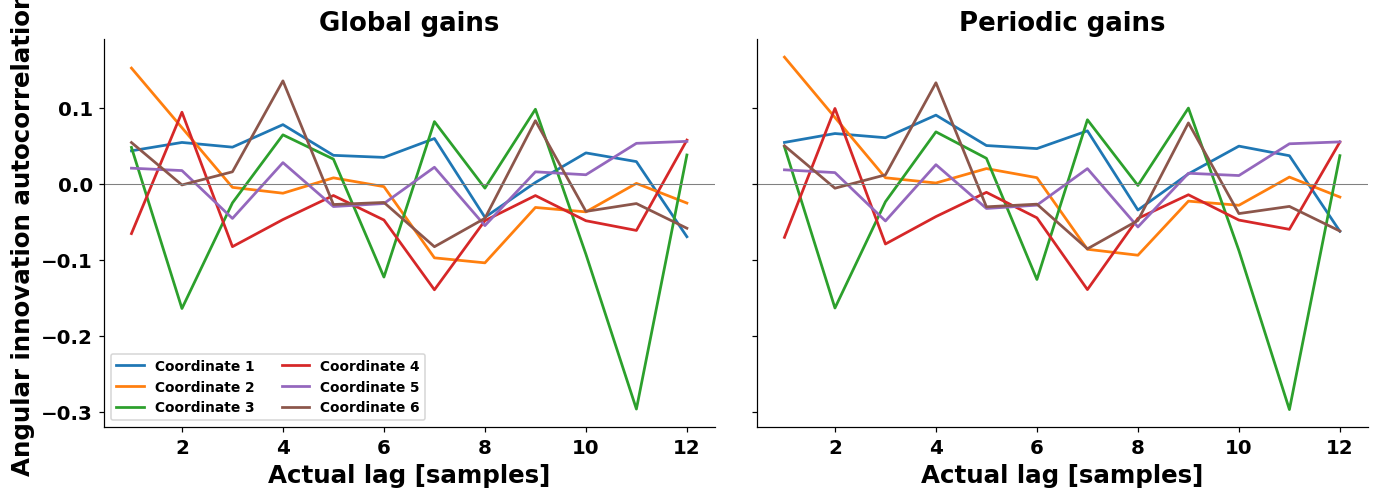

**Purpose:** Common lag and correlation scales compare innovation autocorrelation while preserving gaps.

**Result:** Global gains show 0 whiteness rejections in 24 eligible runs. Periodic gains show 0 whiteness rejections in 24 eligible runs.

**Global gains.** **G:** No detectable command–innovation correlation over the tested lags. **H:** The eligible runs show no detectable serial dependence at the tested lags.

**Periodic gains.** **G:** No detectable command–innovation correlation over the tested lags. **H:** The eligible runs show no detectable serial dependence at the tested lags.

| Model | G: command–innovation p | H: Ljung–Box rejections | Eligible runs |
| --- | --- | --- | --- |
| Global gains | 0.715 | 0 | 24 |
| Periodic gains | 0.62 | 0 | 24 |

**Additional check.** ADF and KPSS on the raw periodic-model innovations describe their level behavior. Ljung–Box above tests whiteness.

| Raw innovation | Test seed | Consecutive samples | ADF p | KPSS p* | Reading |
| --- | --- | --- | --- | --- | --- |
| LSO 1 alpha | 8960 | 63 | 0.495 | 0.0866 | inconclusive / low power |
| LSO 1 delta | 8960 | 63 | 2.97e-14 | 0.1 | supports level stationarity |
| LSO 2 alpha | 8960 | 30 | 0.99 | 0.0935 | inconclusive / low power |
| LSO 2 delta | 8960 | 30 | 0.0402 | 0.1 | supports level stationarity |
| LSO 3 alpha | 8960 | 71 | 0.9 | 0.01 | evidence against level stationarity |
| LSO 3 delta | 8960 | 71 | 2.11e-12 | 0.1 | supports level stationarity |

In [6]:
reports={label:ld.residual_report(updated['standardized'],test.u,orbit.settings['residual_lags'])
         for label,(updated,_) in predictions.items()}
residual=reports['Periodic gains']
plots.compare_angular_residuals(reports,OUT/'figures')
diagnostic_rows = []
for label, q in reports.items():
    adjusted = q['ljung_box_holm_p']
    rejected = np.argwhere(adjusted < alpha)
    n = q['eligible_whiteness_tests']
    p = q['ccf_global_p']
    diagnostic_rows.append(dict(model=label,rejects=len(rejected),eligible=n,
                                g_p=p,max_command_lag_samples=q['lags']+1))
    if n == 0:
        h_reading = 'Visibility left no runs long enough to test whiteness.'
    elif len(rejected):
        runs = ', '.join(f'seed {test.seeds[a]}, coordinate {c+1} (adjusted p={adjusted[a,c]:.3g})'
                         for a,c in rejected)
        h_reading = f'Some prediction errors retain time structure. Rejected runs: {runs}.'
    else:
        h_reading = 'The eligible runs show no detectable serial dependence at the tested lags.'
    if p is None:
        g_reading = 'Too few usable command–innovation pairs to test the burn response.'
    elif p < alpha:
        g_reading = 'Past burns still predict part of the innovation. Revisit the command-to-angle model.'
    else:
        g_reading = 'No detectable command–innovation correlation over the tested lags.'
    display(Markdown(f'**{label}.** **G:** {g_reading} **H:** {h_reading}'))
table(['Model','G: command–innovation p','H: Ljung–Box rejections','Eligible runs'],
      [(r['model'],test_p(r['g_p']),r['rejects'],r['eligible']) for r in diagnostic_rows])
print('Eligible runs use at least 24 consecutive samples. The input screen covers command-to-angle '
      f'delays of 1–{diagnostic_rows[0]["max_command_lag_samples"]} samples.')
(OUT/'gain_model_diagnostics.json').write_text(json.dumps(diagnostic_rows,indent=2)+'\n')
# Retain an angle-by-angle stationarity check for the periodic predictor.
innovation_rows = ld.stationarity_rows(pred['residual'] / ARCSEC)
display(Markdown('**Additional check.** ADF and KPSS on the raw periodic-model '
                 'innovations describe their level behavior. Ljung–Box above tests whiteness.'))
table(['Raw innovation','Test seed','Consecutive samples','ADF p','KPSS p*','Reading'],
      [(r['channel'],test.seeds[r['arc']],r['contiguous_samples'],test_p(r['adf_p']),
        test_p(r['kpss_p']),r['reading']) for r in innovation_rows])
(OUT/'innovation_stationarity.json').write_text(json.dumps(innovation_rows,indent=2)+'\n')
np.savez_compressed(OUT/'residual_checks.npz',**{k:v for k,v in residual.items() if isinstance(v,np.ndarray)})
(OUT/'optical_residual_summary.json').write_text(json.dumps({k:v for k,v in residual.items() if not isinstance(v,np.ndarray)},indent=2)+'\n')

## 6. Do the burn commands keep the spacecraft within the corridor?

Guidance uses only the LSO-derived departure estimate, with state updates at every measurement sample and planner calls at every measurement sample (about 1.5 hours). Candidate burns are checked by nonlinear propagation. The one-year run reports sampled corridor performance and the cumulative commanded Δv from the actual simulated impulses.

Both runs use the revised extended navigation filter and the same single-burn planner, which targets 30% of the corridor limits. The filter propagates the estimated state with nonlinear dynamics, recomputes its local STM and visible angle Jacobians, and accounts for impulse uncertainty. The initial departure, angle-noise seed and measurement cadence are fixed. The side-by-side plots isolate the choice of a global or periodic actuator gain fit for this simulated year.

| Gains with revised filter | Completed | First exit [day] | Peak position [km] | Peak velocity [m/s] | Burns | Commanded Δv [m/s] |
| --- | --- | --- | --- | --- | --- | --- |
| Global gains | Yes | No exit | 3.05 | 0.0846 | 395 | 6.47 |
| Periodic gains | Yes | 91.8 | 3.24 | 0.106 | 414 | 6.61 |

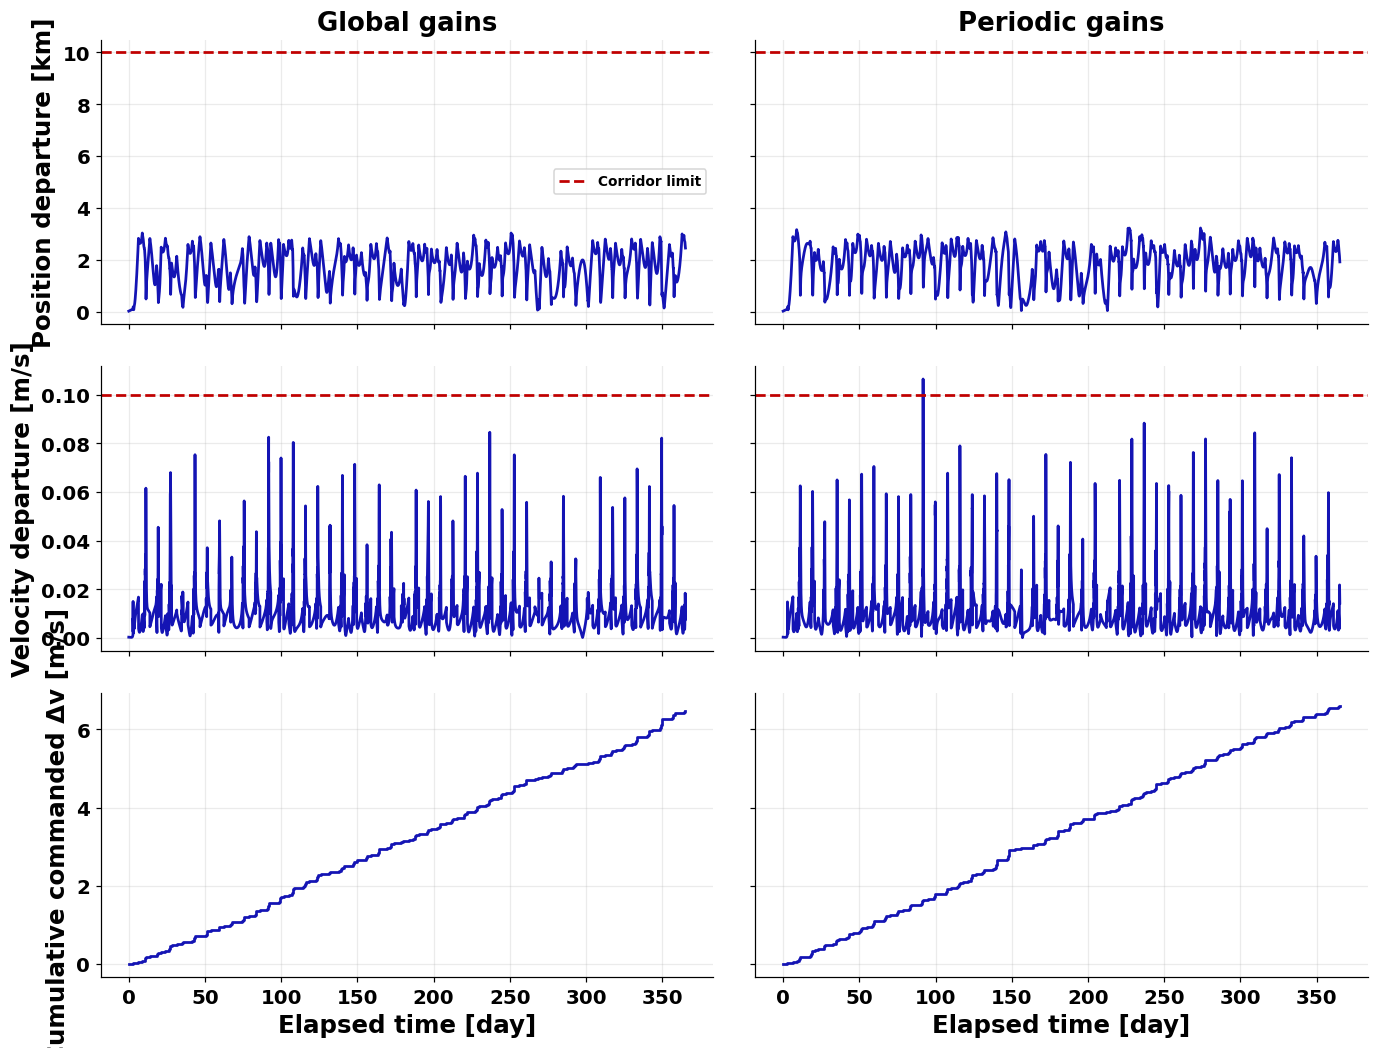

**Purpose:** Compare true departures and accumulated commands with the same filter, planner and starting conditions.

**Result:** Global gains stayed inside both limits and commanded 6.47 m/s. Periodic gains did not meet the full-year corridor and commanded 6.61 m/s.

| Metric | Observed value |
| --- | --- |
| completed | True |
| requested_duration_days | 365.25 |
| last_day | 365.25 |
| planning_stride_steps | 1 |
| planning_margin | 0.3 |
| maximum_position_km | 3.2392837150802745 |
| maximum_velocity_m_s | 0.10644328445444824 |
| all_evaluated_samples_inside | False |
| first_sampled_exit_day | 91.78647970791823 |
| burns | 414 |
| total_commanded_delta_v_m_s | 6.607793129888127 |
| annual_delta_v_m_s | 6.607793129888127 |
| visible_epoch_fraction | 0.9960358497069975 |

**Global gains.** Every evaluated sample stayed inside both corridor limits for the full year.

**Periodic gains.** First corridor violation on day 91.79. Cumulative commanded Δv includes burns after the violation.

The paired comparison uses one starting departure and one observation-noise seed.

In [7]:
trials={model:sk.stationkeeping_trial(
    orbit,model_gains, navigation='extended', seed=26960,
    duration_days=orbit.settings['annual_horizon_days'],
    planning_stride_steps=orbit.settings['annual_planning_stride_steps'],
    stop_on_departure_cutoff=False)
    for model,model_gains in models.items()}
trial=trials['Periodic gains']
comparison={model:result['summary'] for model,result in trials.items()}
(OUT/'annual_model_comparison.json').write_text(json.dumps(comparison,indent=2)+'\n')
def annual_metric(value):
    return '—' if value is None else f'{value:.3g}'
table(['Gains with revised filter','Completed','First exit [day]','Peak position [km]',
       'Peak velocity [m/s]','Burns','Commanded Δv [m/s]'],
      [(model,'Yes' if q['completed'] else 'No',
        'No exit' if q['first_sampled_exit_day'] is None else annual_metric(q['first_sampled_exit_day']),
        annual_metric(q['maximum_position_km']),annual_metric(q['maximum_velocity_m_s']),
        q['burns'],annual_metric(q['annual_delta_v_m_s']))
       for model,q in comparison.items()])
plots.compare_annual(orbit,trials,OUT/'figures')
summary=trial['summary']
table(['Metric','Observed value'],[(k,summary[k]) for k in ('completed','requested_duration_days','last_day','planning_stride_steps','planning_margin','maximum_position_km','maximum_velocity_m_s','all_evaluated_samples_inside','first_sampled_exit_day','burns','total_commanded_delta_v_m_s','annual_delta_v_m_s','visible_epoch_fraction')])
np.savez_compressed(OUT/'closed_loop.npz',**{k:v for k,v in trial.items() if k!='summary'})
(OUT/'closed_loop_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
for model, q in comparison.items():
    exit_day = q['first_sampled_exit_day']
    if exit_day is not None:
        reading = (f'First corridor violation on day {exit_day:.2f}. '
                   'Cumulative commanded Δv includes burns after the violation.')
    elif q['completed']:
        reading = 'Every evaluated sample stayed inside both corridor limits for the full year.'
    else:
        reading = 'The run ended before the full year without an observed corridor violation.'
    display(Markdown(f'**{model}.** {reading}'))
display(Markdown('The paired comparison uses one starting departure and one observation-noise seed.'))

## 7. What the grey box can support

For the saved experiment, the grey box supports orbit estimation. The angular updates improve held-out position and velocity estimates, and the global gain fit is the simpler baseline favored by BIC and validation. Some measured offsets, including LSO 3 declination, show evidence against a constant level. The held-out tests find no detectable dependence on past burns or violations of whiteness in the eligible standardized innovation runs. These findings apply to the measured phases and lags. The paired annual trial has one starting departure and one noise seed, so it gives an example of corridor performance for each model.

For guidance, compare the single-burn planner against **output-feedback model predictive control (MPC)**, which can optimize several future burns under corridor and command constraints and replan as new estimates arrive. Also benchmark the differential-correction and minimization variants of x-axis crossing targeting, with and without covariance-aware prediction, from Shimane et al. (arXiv:2512.01182v4). Use matched starting departures and noise seeds to compare full-year corridor passes and cumulative commanded $\Delta v$.

For identification, investigate phase- and visibility-dependent innovation structure before adding parameters. A local output-error (OE) benchmark assumes noise at the angle output. A local Box–Jenkins (BJ) benchmark can model a separate colored disturbance path if the records support estimating it. Compare both paths on independent trajectories in the same phase and visibility ranges.